# MCP config census: analysis

How are MCP servers configured in public GitHub repositories, and how often do those configs
contain the risks [agentscan](https://github.com/SonawaneMayur/agentscan) detects?

This notebook reads **only the aggregated tables in `results/`**, which contain no repository
names, file paths or secret values. Method, ethics and limitations are in [README.md](README.md).
Charts are saved to `figures/`.

> **To re-run:** `uv run --group demo jupyter nbconvert --to notebook --execute --inplace research/mcp-config-census/analyze.ipynb`

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

if Path.cwd().name != "mcp-config-census":
    os.chdir(Path("research/mcp-config-census"))
RESULTS, FIGURES = Path("results"), Path("figures")
FIGURES.mkdir(exist_ok=True)
pd.set_option("display.max_colwidth", None)

summary = json.loads((RESULTS / "summary.json").read_text())
# Every table here is an aggregate: no per-repo or per-file rows are published.

In [2]:
# Shared chart style: recessive axes, direct value labels, status colors only for severity.
SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE = "#2a78d6"
SEVERITY = {"high": "#ec835a", "medium": "#fab219", "any": "#52514e"}


def bar_chart(
    labels,
    values,
    title,
    colors=BLUE,
    fmt="{:,.0f}",
    xlabel=None,
    note=None,
    size=(10, 4),
    value_labels=None,
    headroom=1.15,
):
    fig, ax = plt.subplots(figsize=size, facecolor=SURFACE)
    ax.set_facecolor(SURFACE)
    bars = ax.barh(labels, values, height=0.6, color=colors)
    ax.invert_yaxis()
    ax.set_title(title, loc="left", color=INK, fontsize=13, fontweight="bold", pad=14)
    ax.tick_params(colors=MUTED, length=0, labelsize=10.5)
    ax.xaxis.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right", "bottom"):
        ax.spines[side].set_visible(False)
    ax.spines["left"].set_color(GRID)
    top = max(values)
    texts = value_labels or [fmt.format(v) for v in values]
    for bar, text in zip(bars, texts, strict=False):
        ax.text(
            bar.get_width() + top * 0.01,
            bar.get_y() + bar.get_height() / 2,
            text,
            va="center",
            color=INK,
            fontsize=10.5,
        )
    ax.set_xlim(0, top * headroom)
    if xlabel:
        ax.set_xlabel(xlabel, color=MUTED)
    if note:
        fig.text(0.01, 0.01, note, color=MUTED, fontsize=8.5)
    fig.tight_layout(rect=(0, 0.04 if note else 0, 1, 1))
    return fig


def save(fig, name):
    fig.savefig(FIGURES / name, dpi=200, facecolor=SURFACE)
    plt.show()

## 1. Scope

In [3]:
scope = pd.read_csv(RESULTS / "by_path_kind.csv")
print(
    f"Collected {summary['collected_files']:,} files ({summary['collected_unique_contents']:,} unique contents)."
)
print(
    f"Analyzed: {summary['analyzed_files']:,} real config files in {summary['analyzed_repos']:,} repositories,"
)
print(
    f"defining {summary['servers_in_unique_contents']:,} MCP servers (counted per unique file content)."
)
print(
    f"Window: {summary['collection_window_utc'][0][:10]}; agentscan {summary['agentscan_version']}"
)
scope

Collected 96,425 files (76,617 unique contents).
Analyzed: 84,813 real config files in 72,243 repositories,
defining 119,187 MCP servers (counted per unique file content).
Window: 2026-10-18; agentscan 0.1.2


,path_kind,files,repos,pct_any_finding,pct_likely_real_secret,pct_MCP001,pct_MCP002,pct_MCP003
0,config,76516,67367,37.6,3.2,4.0,35.6,0.4
1,plugin,8297,5606,15.0,0.3,0.6,14.4,0.1
2,other_name,6332,4813,38.9,3.9,9.9,33.0,0.8
3,test_or_example,3457,2187,33.2,2.2,7.3,28.4,1.4


`config` and `plugin` files are the analysis scope. `other_name` (for example `.mcp.json.example`)
and `test_or_example` (files under test, example, template or benchmark folders) are excluded from
headline numbers but shown here for transparency. They have *higher* finding rates, as expected for
sample files.

## 2. How common is each risk?

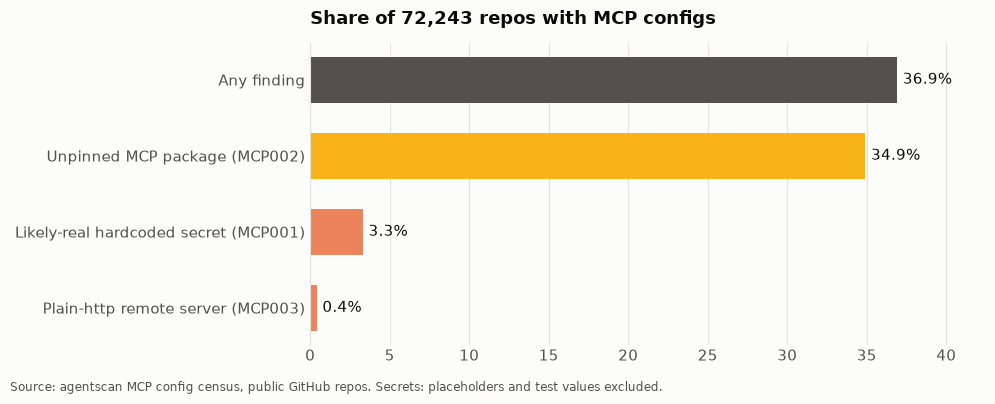

,measure,repos,pct_repos,severity
0,Any finding,26673,36.9,any
1,Unpinned MCP package (MCP002),25227,34.9,medium
2,Likely-real hardcoded secret (MCP001),2356,3.3,high
3,Plain-http remote server (MCP003),286,0.4,high


In [4]:
headline = pd.read_csv(RESULTS / "headline.csv")
n_repos = summary["analyzed_repos"]
fig = bar_chart(
    headline.measure,
    headline.pct_repos,
    f"Share of {n_repos:,} repos with MCP configs",
    colors=[SEVERITY[s] for s in headline.severity],
    fmt="{:.1f}%",
    note="Source: agentscan MCP config census, public GitHub repos. Secrets: placeholders and test values excluded.",
)
save(fig, "1-risk-prevalence.png")
headline

## 3. Hardcoded secrets

2,426 of 3,044 secret findings look real; 618 (20%) were placeholders, test values or too short/random.


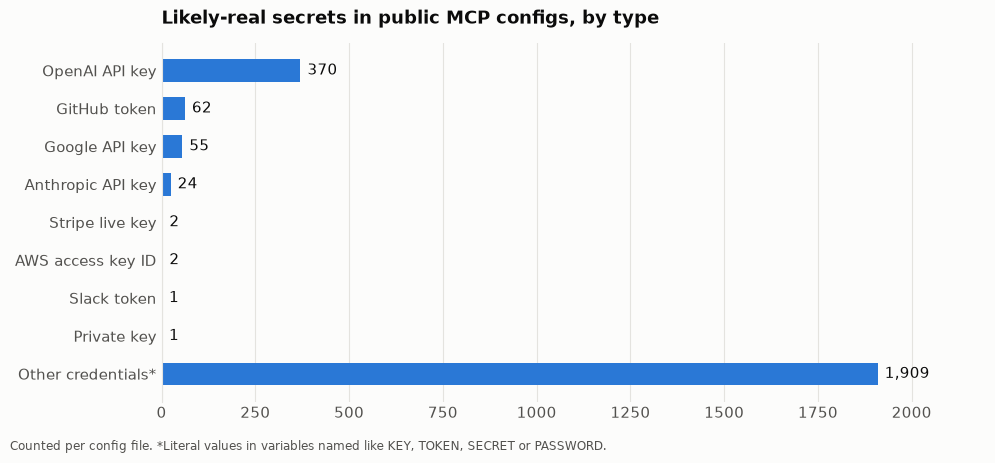

,likely_real,low_entropy,placeholder,too_short,total
secret_kind,,,,,
credential,1909,30,381,171,2491
OpenAI API key,370,0,15,0,385
GitHub token,62,0,10,0,72
Google API key,55,0,0,0,55
Anthropic API key,24,0,2,0,26
Slack token,1,0,8,0,9
Stripe live key,2,0,1,0,3
AWS access key ID,2,0,0,0,2
private key,1,0,0,0,1


In [5]:
quality = pd.read_csv(RESULTS / "secret_quality.csv").set_index("secret_kind")
excluded = quality.total.sum() - quality.likely_real.sum()
print(
    f"{quality.likely_real.sum():,} of {quality.total.sum():,} secret findings look real; "
    f"{excluded:,} ({100 * excluded / quality.total.sum():.0f}%) were placeholders, test values or too short/random."
)
named = quality.drop(index="credential").likely_real.sort_values(ascending=False)
named = named[named > 0]
labels = [k[0].upper() + k[1:] for k in named.index] + ["Other credentials*"]
values = list(named.values) + [quality.loc["credential", "likely_real"]]
fig = bar_chart(
    labels,
    values,
    "Likely-real secrets in public MCP configs, by type",
    note="Counted per config file. *Literal values in variables named like KEY, TOKEN, SECRET or PASSWORD.",
    size=(10, 4.6),
)
save(fig, "2-secret-types.png")
quality

Most of these are **service tokens** (for databases, documentation and search APIs and other
hosted services), usually in env vars or an **`Authorization` header** on a remote server.
Which variable names hold them is deliberately not published: it would work as a search recipe
for attackers. Every one has a safe alternative: an env var reference such as
`"${SERVICE_API_TOKEN}"`, or the client's secret input.

## 4. Supply chain: are MCP packages pinned?

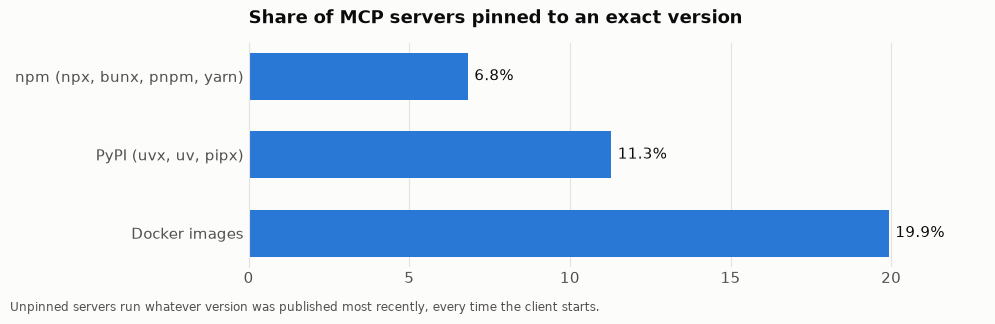

,ecosystem,launcher,servers,pinned,pct_pinned
0,npm,bunx,1029,71,6.9
1,npm,npx,36788,2495,6.8
2,npm,pnpm,279,35,12.5
3,npm,yarn,15,1,6.7
4,pypi,pipx,25,4,16.0
5,pypi,uv,104,3,2.9
6,pypi,uvx,4539,520,11.5


In [6]:
pinning = pd.read_csv(RESULTS / "pinning.csv")
extras = pd.read_csv(RESULTS / "extras.csv").set_index("measure")["count"]
by_eco = pinning.groupby("ecosystem")[["servers", "pinned"]].sum()
rows = [
    ("npm (npx, bunx, pnpm, yarn)", by_eco.loc["npm", "pinned"] / by_eco.loc["npm", "servers"]),
    ("PyPI (uvx, uv, pipx)", by_eco.loc["pypi", "pinned"] / by_eco.loc["pypi", "servers"]),
    ("Docker images", extras["docker_images_pinned"] / extras["docker_servers"]),
]
fig = bar_chart(
    [r[0] for r in rows],
    [100 * r[1] for r in rows],
    "Share of MCP servers pinned to an exact version",
    fmt="{:.1f}%",
    size=(10, 3.2),
    note="Unpinned servers run whatever version was published most recently, every time the client starts.",
)
save(fig, "3-pinning.png")
pinning

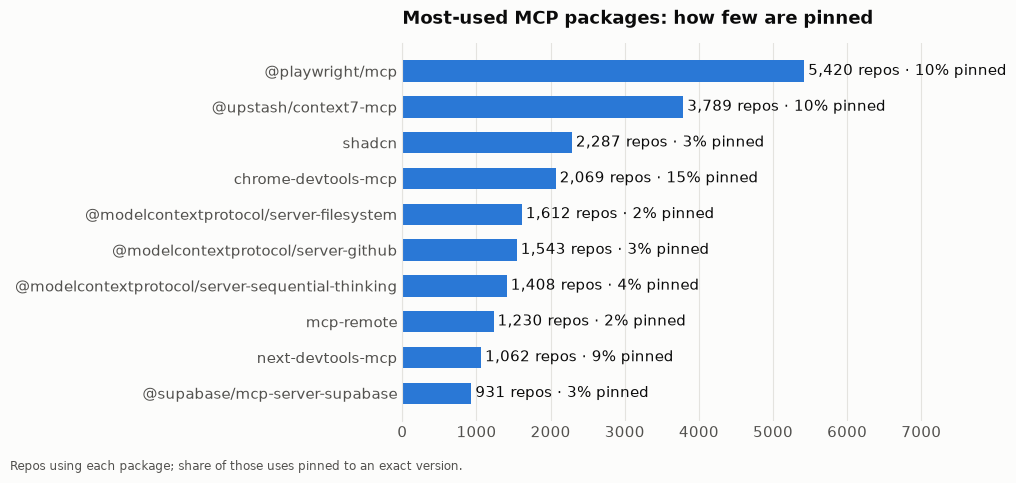

,package,ecosystem,repos,pct_pinned
0,@playwright/mcp,npm,5420,9.5
1,@upstash/context7-mcp,npm,3789,10.1
2,shadcn,npm,2287,2.9
3,chrome-devtools-mcp,npm,2069,15.2
4,@modelcontextprotocol/server-filesystem,npm,1612,1.8
5,@modelcontextprotocol/server-github,npm,1543,3.0
6,@modelcontextprotocol/server-sequential-thinking,npm,1408,4.0
7,mcp-remote,npm,1230,2.1
8,next-devtools-mcp,npm,1062,8.8
9,@supabase/mcp-server-supabase,npm,931,3.2


In [7]:
top = pd.read_csv(RESULTS / "top_packages.csv").head(10)
fig = bar_chart(
    top.package,
    top.repos,
    "Most-used MCP packages: how few are pinned",
    size=(10, 4.8),
    value_labels=[
        f"{r:,} repos · {p:.0f}% pinned" for r, p in zip(top.repos, top.pct_pinned, strict=False)
    ],
    headroom=1.45,
    note="Repos using each package; share of those uses pinned to an exact version.",
)
save(fig, "4-top-packages.png")
top

## 5. By client

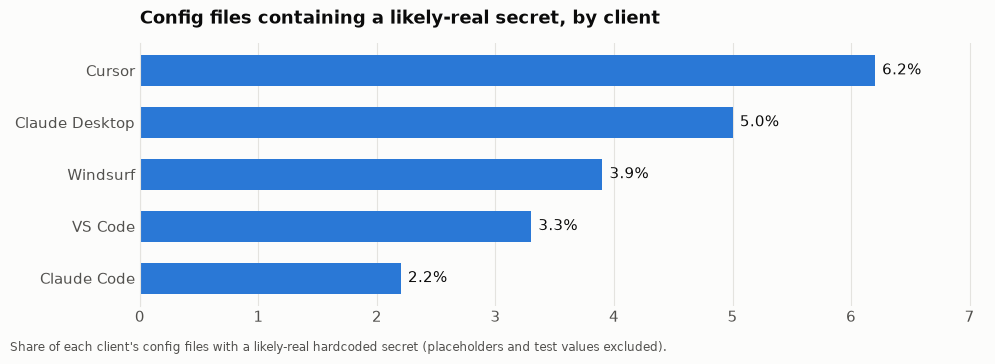

,files,repos,pct_likely_real_secret,pct_any_finding
client,,,,
cursor,7979,7977,6.2,43.7
claude-desktop,2272,2039,5.0,28.5
windsurf,4938,3932,3.9,36.3
vscode,15014,15013,3.3,40.7
claude-code,54610,47534,2.2,32.9


In [8]:
clients = (
    pd.read_csv(RESULTS / "by_client.csv")
    .set_index("client")
    .sort_values("pct_likely_real_secret", ascending=False)
)
names = {
    "claude-desktop": "Claude Desktop",
    "cursor": "Cursor",
    "windsurf": "Windsurf",
    "vscode": "VS Code",
    "claude-code": "Claude Code",
}
fig = bar_chart(
    [names[c] for c in clients.index],
    clients.pct_likely_real_secret,
    "Config files containing a likely-real secret, by client",
    fmt="{:.1f}%",
    size=(10, 3.6),
    note="Share of each client's config files with a likely-real hardcoded secret (placeholders and test values excluded).",
)
save(fig, "5-clients.png")
clients[["files", "repos", "pct_likely_real_secret", "pct_any_finding"]]

## 6. Other measures

In [9]:
transport = pd.read_csv(RESULTS / "transport.csv").set_index("transport").servers
print(
    f"Servers: {transport.sum():,} ({100 * transport['remote'] / transport.sum():.0f}% remote, "
    f"{100 * transport['stdio'] / transport.sum():.0f}% local stdio)"
)
print(
    f"Filesystem servers given a whole disk or home folder: {extras['filesystem_broad_path']:,} "
    f"of {extras['filesystem_servers']:,}"
)
per_file = pd.read_csv(RESULTS / "servers_per_file.csv")
print(f"Files defining a single server: {100 * per_file.files.iloc[0] / per_file.files.sum():.0f}%")
pd.read_csv(RESULTS / "remote_schemes.csv")

Servers: 119,187 (28% remote, 71% local stdio)
Filesystem servers given a whole disk or home folder: 65 of 1,696
Files defining a single server: 71%


,url_scheme,local,servers
0,file,remote host,2
1,htps,remote host,1
2,http,local,5391
3,http,remote host,371
4,https,local,29
5,https,remote host,27268
6,localhost,remote host,2
7,npx,remote host,26
8,replace,remote host,1
9,ws,local,2
